<a href="https://colab.research.google.com/github/dka0086/Analise-de-rede-de-grafos-Olist/blob/main/Olist_analise.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Olist: rede de categorias por co-compra

Continuação do `Produtos_Olist.ipynb`. Este notebook substitui as células 7 a 10 do original (a bipartida clientes x produtos) e segue até a exportação para o Gephi.

**Pergunta:** quais categorias de produto fazem a ponte entre grupos de consumo no e-commerce brasileiro, e os hubs mais populares são também os que mais conectam grupos?

**Modelagem principal (rede A):**
- Bipartida: pedidos x categorias, só pedidos com 2 ou mais categorias distintas.
- Projeção: categorias ligadas quando aparecem no mesmo pedido. Não dirigida. Peso por contagem e por Jaccard.
- Fica de fora: pedidos de uma categoria só, pedidos cancelados ou indisponíveis, itens sem categoria, preço e frete.

**Comparação (rede B):** vendedores x categorias, projetada do mesmo jeito.

Cada bloco de análise termina com uma célula de texto para vocês escreverem a interpretação. É ali que o critério "Análise e interpretação" pontua.

## 0. Carga dos dados

In [1]:
# Instalação (só a primeira vez no Colab)
!pip install -q nxviz plotly

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 332.3/332.3 kB 5.1 MB/s eta 0:00:00


In [2]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from networkx.algorithms import bipartite
from scipy import sparse
from scipy.stats import spearmanr
import nxviz as nv
from nxviz import annotate
from matplotlib.lines import Line2D
import seaborn as sns
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

DATA_DIR = Path(os.environ.get("OLIST_DATA", "data/"))
FIG_DIR = Path("figuras")
FIG_DIR.mkdir(exist_ok=True)

orders = pd.read_csv(DATA_DIR / "olist_orders_dataset.csv")
order_items = pd.read_csv(DATA_DIR / "olist_order_items_dataset.csv")
products = pd.read_csv(DATA_DIR / "olist_products_dataset.csv")
product_category = pd.read_csv(
    DATA_DIR / "product_category_name_translation.csv", encoding="utf-8-sig"
)
print(orders.shape, order_items.shape, products.shape, product_category.shape)

(99441, 8) (112650, 7) (32951, 9) (71, 2)


In [3]:
from matplotlib.colors import LinearSegmentedColormap

# Paleta categórica validada (daltonismo): use as cores na ordem, sem repetir
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
COR_OUTRAS, COR_NEUTRA = "#9A9A9A", "#B9B8B3"
# Escala sequencial de um matiz só (claro = pouco, escuro = muito)
SEQ = LinearSegmentedColormap.from_list(
    "seq_azul", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=CAT)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

## 1. Tabela de itens com categoria e passo zero

Criando a tabela de itens, produtos cancelados ou indisponiveis saem. A tabela de itens é composta por informações relevantes para a construção da rede das tabelas de pedidos e com uma coluna de categorias em inglês.

In [4]:
STATUS_FORA = ["canceled", "unavailable"]
col_en = product_category.columns[1]  # product_category_name_english

pedidos_validos = orders.loc[~orders["order_status"].isin(STATUS_FORA), "order_id"]

itens = (
    order_items[["order_id", "product_id", "seller_id"]]
    .merge(products[["product_id", "product_category_name"]], on="product_id", how="left")
    .merge(product_category, on="product_category_name", how="left")
)
itens = itens[itens["order_id"].isin(pedidos_validos)].copy()
itens["categoria"] = itens[col_en].fillna(itens["product_category_name"])
itens = itens.dropna(subset=["categoria"])
itens.drop(columns=["product_category_name", col_en], inplace=True)

print("itens:", len(itens), "| categorias:", itens["categoria"].nunique())
itens.head()

itens: 110512 | categorias: 73


,order_id,product_id,seller_id,categoria
0,00010242fe8c5a6d1ba2dd792cb16214,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,pet_shop
2,000229ec398224ef6ca0657da4fc703e,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,furniture_decor
3,00024acbcdf0a6daa1e931b038114c75,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,perfumery
4,00042b26cf59d7ce69dfabb4e55b4fd9,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,garden_tools


## 1.1 Numero de Categorias

Coleta e conta pedidos com base no número de categorias

In [5]:
ncat = itens.groupby("order_id")["categoria"].nunique()
dist = ncat.value_counts().sort_index()
n_multi = int((ncat >= 2).sum())

print(f"Pedidos com categoria: {len(ncat):,}")
print(f"Pedidos com 2+ categorias: {n_multi:,} ({n_multi / len(ncat):.1%})")
display(dist.head(8).rename("pedidos").to_frame().rename_axis("categorias no pedido"))

Pedidos com categoria: 96,824
Pedidos com 2+ categorias: 726 (0.7%)


,pedidos
categorias no pedido,
1,96098
2,711
3,15


**Interpretação:** Para a construção da Rede A, serão utilizados apenas 726 pedidos (0,7% do total), o que indica que a grande maioria das compras na plataforma contém produtos de uma única categoria. Como so pedidos com duas ou mais categoria entram na rede, o grafo vai representar o comportamento de compra combinada entre diferentes categorias.

## 2. Bipartida pedidos x categorias (semana 2)

In [6]:
multi = ncat[ncat >= 2].index
pares = itens.loc[itens["order_id"].isin(multi), ["order_id", "categoria"]].drop_duplicates()

B = nx.Graph()
B.add_nodes_from(pares["order_id"].unique(), node_type="pedido")
B.add_nodes_from(pares["categoria"].unique(), node_type="categoria")
B.add_edges_from(pares.itertuples(index=False, name=None))

print("nós:", B.number_of_nodes(), "| arestas:", B.number_of_edges())
print("bipartida?", bipartite.is_bipartite(B))
invalidas = [(u, v) for u, v in B.edges() if B.nodes[u]["node_type"] == B.nodes[v]["node_type"]]
print("arestas inválidas:", len(invalidas))

nós: 787 | arestas: 1467
bipartida? True
arestas inválidas: 0


## 3. Projeção: contagem e Jaccard (semana 6)

A função abaixo faz a projeção pela matriz de incidência (BᵀB), contando as co-ocorrencias, e calcula os dois pesos:
- **contagem:** número de pedidos em que as duas categorias aparecem juntas;
- **Jaccard:** contagem dividida pelo número de pedidos que têm uma ou outra.

In [7]:
def criar_rede(df, unidade, item):
    # Projeta a bipartida unidade x item numa rede de itens.
    # Retorna (G_contagem, G_jaccard), ambas com os mesmos nós e arestas.
    df = df[[unidade, item]].drop_duplicates()
    unidades = df[unidade].unique()
    itens_ = np.sort(df[item].unique())
    linha = pd.Series(np.arange(len(unidades)), index=unidades).loc[df[unidade]].to_numpy()
    coluna = pd.Series(np.arange(len(itens_)), index=itens_).loc[df[item]].to_numpy()
    m_incidence = sparse.csr_matrix((np.ones(len(df)), (linha, coluna)), shape=(len(unidades), len(itens_)))
    cooccurrence = (m_incidence.T @ m_incidence).tocoo()
    tam = np.asarray(m_incidence.sum(axis=0)).ravel()  # unidades por item

    Gc, Gj = nx.Graph(), nx.Graph()
    for k, nome in enumerate(itens_):
        Gc.add_node(nome, n_unidades=int(tam[k]))
        Gj.add_node(nome, n_unidades=int(tam[k]))
    for a, b, w in zip(cooccurrence.row, cooccurrence.col, cooccurrence.data):
        if a < b:
            Gc.add_edge(itens_[a], itens_[b], weight=float(w))
            Gj.add_edge(itens_[a], itens_[b], weight=float(w / (tam[a] + tam[b] - w)))
    return Gc, Gj


G_cont, G_jac = criar_rede(pares, "order_id", "categoria")
print("categorias:", G_cont.number_of_nodes(), "| arestas:", G_cont.number_of_edges())

categorias: 61 | arestas: 243


**Interpretação:** São criados dois grafos a partir da rede A, o G_cont é um grafo que tem como peso nas suas arestas a quantidade de co-ocorrencia, e o G_jac usa o grau de similaridade de Jaccard como peso. A importancia desses dois tipos de analise é que, enquando a contagem apenas usa o numero bruto de co-ocorrencias, o indice de Jaccard vai normalizar esse numero pelo total de objetos presente no nas classes categorias e pedidos.


Número de nós:  61 Número de arestas:  243


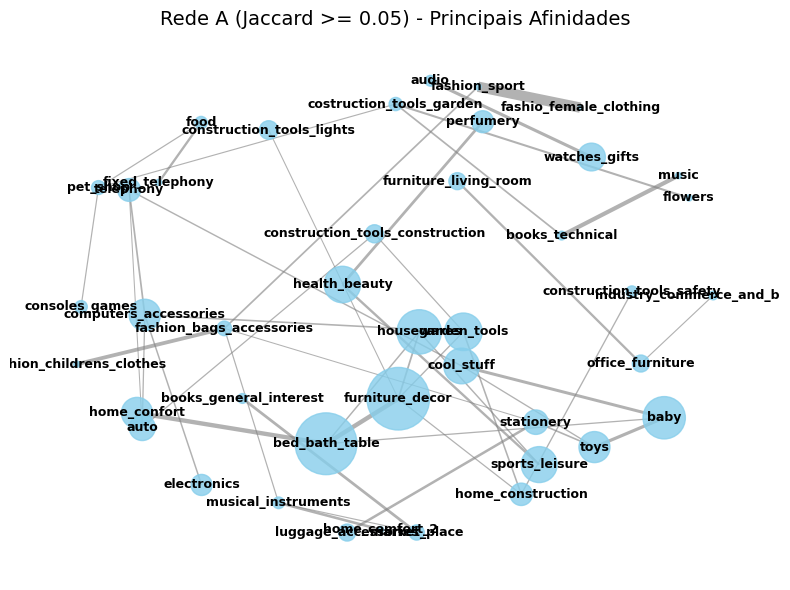

In [8]:
import matplotlib.pyplot as plt
import networkx as nx

limite_jaccard = 0.05

G_filtrado = nx.Graph([
    (u, v, d) for u, v, d in G_jac.edges(data=True)
    if d["weight"] >= limite_jaccard
])

G_filtrado.remove_nodes_from(list(nx.isolates(G_filtrado)))

plt.figure(figsize=(8, 6))
pos = nx.spring_layout(G_filtrado, k=0.5, seed=42)

tamanhos_nos = [
    G_jac.nodes[nó].get("n_unidades", 1) * 10
    for nó in G_filtrado.nodes()
]

largura_arestas = [d["weight"] * 15 for u, v, d in G_filtrado.edges(data=True)]

nx.draw_networkx_nodes(G_filtrado, pos, node_size=tamanhos_nos, node_color="skyblue", alpha=0.8)
nx.draw_networkx_edges(G_filtrado, pos, width=largura_arestas, edge_color="gray", alpha=0.6)
nx.draw_networkx_labels(G_filtrado, pos, font_size=9, font_weight="bold", font_family="sans-serif")

print("Número de nós: ", G_jac.number_of_nodes(), "Número de arestas: ", G_jac.number_of_edges())
plt.title(f"Rede A (Jaccard >= {limite_jaccard}) - Principais Afinidades", fontsize=14)
plt.axis("off")
plt.tight_layout()
plt.show()

## 4. Estrutura básica (semana 2)

nós: 61 | arestas: 243
densidade: 0.133 | grau médio: 8.0
matriz de adjacência: (61, 61) | simétrica: True


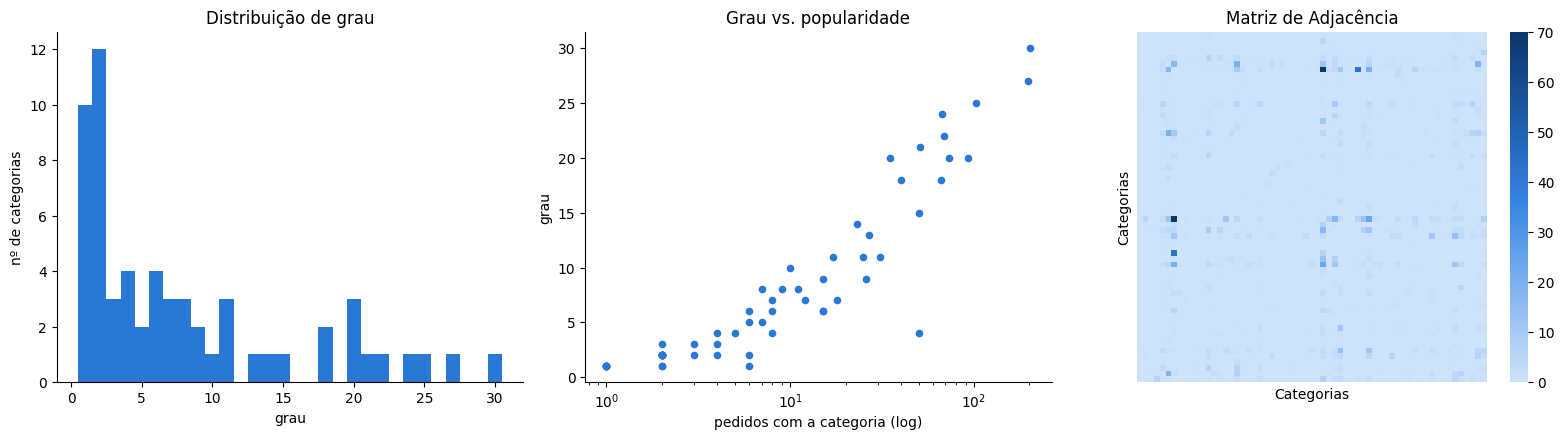

In [9]:
graus = pd.Series(dict(G_jac.degree()))
popularidade = pd.Series(nx.get_node_attributes(G_jac, "n_unidades"))

print("nós:", G_jac.number_of_nodes(), "| arestas:", G_jac.number_of_edges())
print("densidade:", round(nx.density(G_jac), 3), "| grau médio:", round(graus.mean(), 1))
A = nx.to_numpy_array(G_cont)
print("matriz de adjacência:", A.shape, "| simétrica:", bool((A == A.T).all()))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].hist(graus, bins=np.arange(1, int(graus.max()) + 2) - 0.5, color=CAT[0])
ax[0].set(xlabel="grau", ylabel="nº de categorias", title="Distribuição de grau")
ax[1].scatter(popularidade, graus, s=20, color=CAT[0])
ax[1].set(xscale="log", xlabel="pedidos com a categoria (log)", ylabel="grau",
          title="Grau vs. popularidade")

sns.heatmap(
    A,
    ax=ax[2],
    cmap=SEQ,
    cbar=True,
    xticklabels=False,
    yticklabels=False,
    square=True
)
ax[2].set(title="Matriz de Adjacência", xlabel="Categorias", ylabel="Categorias")

plt.tight_layout()
plt.savefig(FIG_DIR / "01_grau_e_matriz.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretação:** A rede tem 61 nós, 243 arestas, densidade 0.13 e grau médio 8. A distribuição de grau é assimétrica, com uma concentração localizada na faixa de 1 a 5, e poucos nós têm grau muito alto. No gráfico de grau vs. popularidade, indica que categorias que aparecem em mais pedidos tendem a ter mais ligações. A matriz de adjacência é simétrica, como esperado em uma rede não direcionada, e o heatmap mostra que é esparsa.  

grau >= 11: 17 de 61 categorias (27.9%)
grau > 11: 23.0%


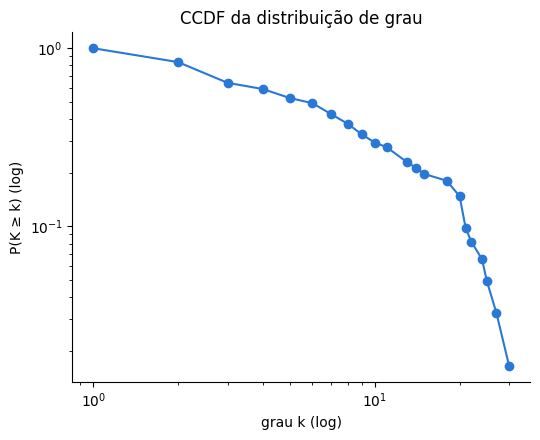

In [10]:
k = graus.values
u = np.unique(k)
ccdf = np.array([(k >= x).mean() for x in u])

pct_ge11 = (graus >= 11).mean() * 100
pct_gt11 = (graus > 11).mean() * 100
n_ge11 = int((graus >= 11).sum())

print(f"grau >= 11: {n_ge11} de {len(graus)} categorias ({pct_ge11:.1f}%)")
print(f"grau > 11: {pct_gt11:.1f}%")

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.loglog(u, ccdf, "o-", color=CAT[0])
ax.set(xlabel="grau k (log)", ylabel="P(K ≥ k) (log)", title="CCDF da distribuição de grau")
plt.tight_layout()
plt.savefig(FIG_DIR / "01b_distribuicao_grau.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretação:** A CCDF (função de distribuição cumulativa complementar) mostra a fração de categorias com grau maior ou igual a k. É outra forma de representar a distribuição de grau e deixa a cauda mais visível que o histograma. A curva decresce lentamente no início, o que indica que a maioria das categorias tem grau baixo. Apenas 23% das categorias têm grau 11 ou mais, e esses poucos nós são os hubs da rede.

In [11]:
n, m = G_jac.number_of_nodes(), G_jac.number_of_edges()
print("grau médio (2m/n):", round(2 * m / n, 2))
print("densidade:", round(nx.density(G_jac), 3),
      "| esparsidade (1 − densidade):", round(1 - nx.density(G_jac), 3))
A = nx.to_numpy_array(G_cont)
print("dirigido:", G_jac.is_directed(), "| matriz simétrica:", np.allclose(A, A.T))

grau médio (2m/n): 7.97
densidade: 0.133 | esparsidade (1 − densidade): 0.867
dirigido: False | matriz simétrica: True


## 4.1 - Componentes, clustering e caminhos (semana 4)

A rede é não dirigida, então componentes fracamente e fortemente conectados coincidem.

In [12]:
comps = sorted(nx.connected_components(G_jac), key=len, reverse=True)
gcc = G_jac.subgraph(comps[0]).copy()

print("componentes:", len(comps), "| isolados:", sum(1 for c in comps if len(c) == 1))
print(f"GCC: {gcc.number_of_nodes()} nós ({gcc.number_of_nodes() / G_jac.number_of_nodes():.0%})")
print("clustering médio:", round(nx.average_clustering(G_jac), 3),
      "| transitividade:", round(nx.transitivity(G_jac), 3))
if gcc.number_of_nodes() > 1:
    print("caminho médio (GCC):", round(nx.average_shortest_path_length(gcc), 2),
          "| diâmetro:", nx.diameter(gcc),
          "| eficiência global:", round(nx.global_efficiency(G_jac), 3))

componentes: 1 | isolados: 0
GCC: 61 nós (100%)
clustering médio: 0.45 | transitividade: 0.387
caminho médio (GCC): 2.28 | diâmetro: 5 | eficiência global: 0.502


## 4.2 - Hubs, pontes e centralidades (semana 4)

Na betweenness ponderada, o peso vira distância (1/peso), porque peso alto significa categorias próximas.

In [13]:
for G in (G_cont, G_jac):
    for u, v, d in G.edges(data=True):
        d["dist"] = 1.0 / d["weight"]

bet_topo = nx.betweenness_centrality(G_jac)
bet_jac = nx.betweenness_centrality(G_jac, weight="dist")
bet_cont = nx.betweenness_centrality(G_cont, weight="dist")

eig = pd.Series(0.0, index=list(G_jac.nodes))
if gcc.number_of_nodes() > 2:
    eig.update(pd.Series(nx.eigenvector_centrality_numpy(gcc, weight="weight")))

cent = pd.DataFrame({
    "pedidos": popularidade,
    "grau": graus,
    "betw_topologica": pd.Series(bet_topo),
    "betw_jaccard": pd.Series(bet_jac),
    "betw_contagem": pd.Series(bet_cont),
    "eigenvector": eig,
})
cent["rank_grau"] = cent["grau"].rank(ascending=False, method="min").astype(int)
cent["rank_betw"] = cent["betw_jaccard"].rank(ascending=False, method="min").astype(int)

rho, _ = spearmanr(cent["grau"], cent["betw_jaccard"])
print("Spearman grau x betweenness (Jaccard):", round(rho, 3))
display(cent.sort_values("betw_jaccard", ascending=False).head(10).round(3))

Spearman grau x betweenness (Jaccard): 0.856


,pedidos,grau,betw_topologica,betw_jaccard,betw_contagem,eigenvector,rank_grau,rank_betw
baby,93,20,0.118,0.262,0.275,0.034,7,1
bed_bath_table,198,27,0.154,0.193,0.454,0.036,2,2
furniture_decor,203,30,0.167,0.164,0.481,0.033,1,3
cool_stuff,66,18,0.074,0.141,0.162,0.024,10,4
stationery,31,11,0.018,0.135,0.029,0.028,15,5
toys,50,15,0.030,0.131,0.071,0.023,12,6
health_beauty,69,22,0.065,0.129,0.133,0.024,5,7
computers_accessories,51,21,0.061,0.121,0.090,0.019,6,8
garden_tools,73,20,0.054,0.117,0.151,0.020,7,9
telephony,27,13,0.034,0.108,0.033,0.014,14,10


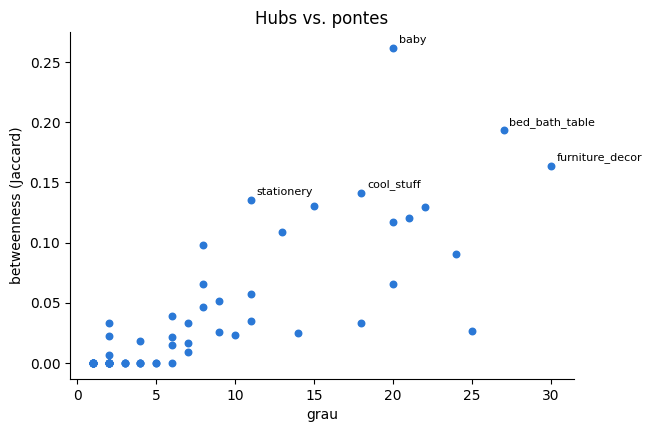

In [14]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.scatter(cent["grau"], cent["betw_jaccard"], s=22, color=CAT[0])
for nome, r in cent.nlargest(5, "betw_jaccard").iterrows():
    ax.annotate(nome, (r["grau"], r["betw_jaccard"]), fontsize=8, xytext=(4, 4),
                textcoords="offset points")
ax.set(xlabel="grau", ylabel="betweenness (Jaccard)", title="Hubs vs. pontes")
plt.savefig(FIG_DIR / "02_grau_vs_betweenness.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretação:** As categorias de maior grau tendem a ter maior betweenness, a categoria baby por exemplo, tem grau 20 com rank 7 em grau, e o primeiro em betweenness. Algumas execeções a essa tendência, categorias com alto graus de betweenness com baixo grau, são, stationery e o toys, essas categorias são classificadas como pontes. O calculo usando arestas ponderada com o indice de Jaccard muda o ranking pois trata arestas com mais peso são tratadas como caminhos curtos, enquanto a topológica trata todas as arestas como iguais e a ponderada por contagem acompanha a popularidade.

Os gráficos de hubs e pontes (circos e arc plot) estão na seção 10, depois que o backbone é calculado.

## Tabela de excentricidade

In [15]:
exc = pd.Series(nx.eccentricity(gcc))
centro, periferia = nx.center(gcc), nx.periphery(gcc)
print("raio:", nx.radius(gcc), "| diâmetro:", nx.diameter(gcc))
print("centro:", sorted(centro))
print("periferia (geométrica):", sorted(periferia))

shell = pd.Series(nx.core_number(G_jac))
print(f"periferia estrutural (k-shell {shell.min()}):", sorted(shell.index[shell == shell.min()]))

cent["excentricidade"] = exc
tab = cent.loc[centro + periferia, ["pedidos", "grau", "excentricidade"]].copy()
tab.insert(0, "posição", ["centro"] * len(centro) + ["periferia"] * len(periferia))
tab = tab.sort_values(["excentricidade", "grau"], ascending=[True, False])
cols = ["pedidos", "grau", "excentricidade"]
display(tab.style.background_gradient(cmap=SEQ, subset=cols, axis=0)
           .format("{:.0f}", subset=cols))

raio: 3 | diâmetro: 5
centro: ['auto', 'baby', 'bed_bath_table', 'fashion_bags_accessories', 'health_beauty', 'musical_instruments', 'stationery']
periferia (geométrica): ['air_conditioning', 'arts_and_craftmanship', 'audio', 'cine_photo', 'computers', 'dvds_blu_ray', 'fashio_female_clothing', 'fixed_telephony', 'flowers', 'food_drink', 'home_construction', 'industry_commerce_and_business', 'music', 'pc_gamer', 'tablets_printing_image']
periferia estrutural (k-shell 1): ['audio', 'christmas_supplies', 'computers', 'fashio_female_clothing', 'fashion_childrens_clothes', 'fashion_shoes', 'fashion_sport', 'home_appliances_2', 'party_supplies', 'pc_gamer', 'signaling_and_security']


,posição,pedidos,grau,excentricidade
bed_bath_table,centro,198,27,3
health_beauty,centro,69,22,3
auto,centro,35,20,3
baby,centro,93,20,3
stationery,centro,31,11,3
fashion_bags_accessories,centro,11,8,3
musical_instruments,centro,7,8,3
home_construction,periferia,26,9,5
cine_photo,periferia,2,3,5
industry_commerce_and_business,periferia,4,3,5


### Qual é o nó mais importante?

In [16]:
corte_grau = cent["grau"].quantile(0.90)
corte_betw = cent["betw_jaccard"].quantile(0.90)

cent["hub"] = cent["grau"] >= corte_grau
cent["ponte"] = (cent["betw_jaccard"] >= corte_betw) & (~cent["hub"])

cols = ["pedidos", "grau", "betw_topologica", "betw_jaccard", "rank_grau", "rank_betw"]
print(f"corte de grau: {corte_grau:.0f} | corte de betweenness: {corte_betw:.3f}")

print("\nHUBS (grau alto):")
display(cent[cent["hub"]].sort_values("grau", ascending=False)[cols])

print("PONTES (betweenness alta sem ser hub):")
display(cent[cent["ponte"]].sort_values("betw_jaccard", ascending=False)[cols])

corte de grau: 20 | corte de betweenness: 0.129

HUBS (grau alto):


,pedidos,grau,betw_topologica,betw_jaccard,rank_grau,rank_betw
furniture_decor,203,30,0.167134,0.163842,1,3
bed_bath_table,198,27,0.154226,0.193220,2,2
housewares,102,25,0.086578,0.026554,3,23
sports_leisure,67,24,0.080407,0.090395,4,12
health_beauty,69,22,0.064647,0.129379,5,7
computers_accessories,51,21,0.061451,0.120621,6,8
auto,35,20,0.090353,0.065819,7,13
baby,93,20,0.118448,0.261582,7,1
garden_tools,73,20,0.053961,0.116949,7,9


PONTES (betweenness alta sem ser hub):


,pedidos,grau,betw_topologica,betw_jaccard,rank_grau,rank_betw
cool_stuff,66,18,0.073764,0.141243,10,4
stationery,31,11,0.017880,0.135028,15,5
toys,50,15,0.029512,0.130508,12,6


In [17]:
cent["closeness"] = pd.Series(nx.closeness_centrality(G_jac))
cols = ["grau", "closeness", "betw_jaccard", "eigenvector"]
cent["rank_medio"] = cent[cols].rank(ascending=False, method="min").mean(axis=1)
top = cent.sort_values("rank_medio").head(10)
display(top[["pedidos"] + cols + ["rank_medio"]].round(3))
print("nó mais importante (rank médio):", top.index[0])
print("líder em cada medida:", {c: cent[c].idxmax() for c in cols})

,pedidos,grau,closeness,betw_jaccard,eigenvector,rank_medio
bed_bath_table,198,27,0.632,0.193,0.036,2.50
furniture_decor,203,30,0.632,0.164,0.033,3.00
baby,93,20,0.583,0.262,0.034,5.25
health_beauty,69,22,0.606,0.129,0.024,6.50
cool_stuff,66,18,0.561,0.141,0.024,8.50
sports_leisure,67,24,0.600,0.090,0.020,9.00
garden_tools,73,20,0.566,0.117,0.020,9.75
computers_accessories,51,21,0.566,0.121,0.019,9.75
housewares,102,25,0.600,0.027,0.024,9.75
auto,35,20,0.588,0.066,0.021,10.00


nó mais importante (rank médio): bed_bath_table
líder em cada medida: {'grau': 'furniture_decor', 'closeness': 'bed_bath_table', 'betw_jaccard': 'baby', 'eigenvector': 'fashion_sport'}


clustering local médio: 0.45 | global (transitividade): 0.387


,pedidos,grau,clustering_local
air_conditioning,2,2,1.000
art,6,2,1.000
drinks,8,4,1.000
dvds_blu_ray,2,2,1.000
food_drink,4,2,1.000
home_comfort_2,2,2,1.000
la_cuisine,2,2,1.000
furniture_bedroom,3,3,1.000
tablets_printing_image,3,2,1.000
home_confort,50,4,0.833


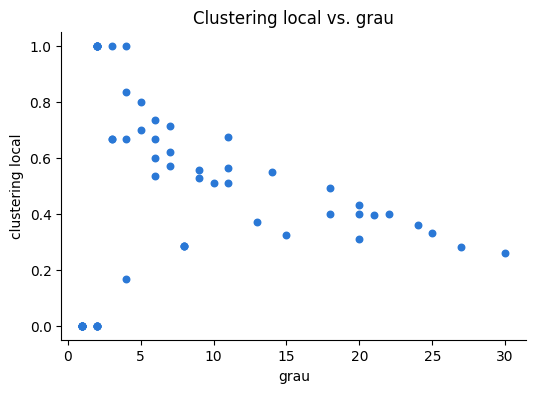

In [18]:
cent["clustering_local"] = pd.Series(nx.clustering(G_jac))
print("clustering local médio:", round(cent["clustering_local"].mean(), 3),
      "| global (transitividade):", round(nx.transitivity(G_jac), 3))
display(cent.sort_values("clustering_local", ascending=False)
        [["pedidos", "grau", "clustering_local"]].head(10).round(3))

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(cent["grau"], cent["clustering_local"], s=22, color=CAT[0])
ax.set(xlabel="grau", ylabel="clustering local", title="Clustering local vs. grau")
plt.savefig(FIG_DIR / "02b_clustering_local.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Núcleo da rede (semana 5)

k máximo: 8
núcleo mais interno: ['auto', 'baby', 'bed_bath_table', 'computers_accessories', 'construction_tools_construction', 'cool_stuff', 'electronics', 'furniture_decor', 'garden_tools', 'health_beauty', 'housewares', 'luggage_accessories', 'perfumery', 'sports_leisure', 'stationery', 'telephony', 'toys', 'watches_gifts']

Categorias de grau alto (quartil superior) fora do núcleo mais interno:


,grau,core,onion,pedidos


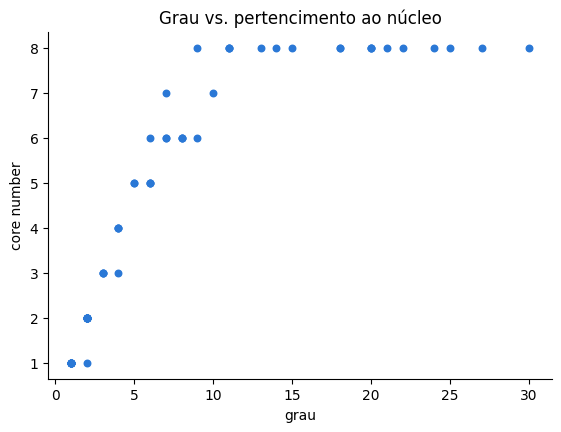

In [19]:
cent["core"] = pd.Series(nx.core_number(G_jac))
cent["onion"] = pd.Series(nx.onion_layers(G_jac))
kmax = int(cent["core"].max())

print("k máximo:", kmax)
print("núcleo mais interno:", sorted(cent.index[cent["core"] == kmax]))

q75 = cent["grau"].quantile(0.75)
fora = cent[(cent["grau"] >= q75) & (cent["core"] < kmax)]
print("\nCategorias de grau alto (quartil superior) fora do núcleo mais interno:")
display(fora[["grau", "core", "onion", "pedidos"]].sort_values("grau", ascending=False))

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.scatter(cent["grau"], cent["core"], s=22, color=CAT[0])
ax.set(xlabel="grau", ylabel="core number", title="Grau vs. pertencimento ao núcleo")
plt.savefig(FIG_DIR / "03_grau_vs_core.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretação:** O núcleo possui 18 categorias que são mais internos com k máximo de 8. Hubs estão presentes nesse núcleo como `furniture_decor`, `bed_bath_table` e `housewares`. As pontes `cool_stuff`, `stationery` e `toys` também formam o núcleo, mesmo tendo um grau inferior. Isso acontece porque o core number depende de os vizinhos também serem bem ligados, e não só de quantas ligações a categoria tem.

## 8. Artefato de clique (semana 6)

Um pedido com muitas categorias liga todas elas entre si e infla a densidade. A tabela mostra como a rede muda ao limitar o tamanho máximo do pedido.

In [20]:
cliques = sorted(nx.find_cliques(G_jac), key=len, reverse=True)
maior = len(cliques[0])
print(f"cliques maximais: {len(cliques)} | maior clique: {maior} categorias")

tab = pd.DataFrame({
    "nº": range(1, sum(len(c) == maior for c in cliques) + 1),
    "tamanho": maior,
    "categorias": [", ".join(sorted(c)) for c in cliques if len(c) == maior],
})
display(tab.style.hide(axis="index")
        .set_properties(subset=["categorias"], **{"text-align": "left"})
        .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}]))

cliques maximais: 110 | maior clique: 8 categorias


nº,tamanho,categorias
1,8,"auto, baby, bed_bath_table, cool_stuff, furniture_decor, health_beauty, housewares, sports_leisure"
2,8,"auto, bed_bath_table, computers_accessories, electronics, furniture_decor, garden_tools, housewares, sports_leisure"
3,8,"auto, bed_bath_table, computers_accessories, cool_stuff, furniture_decor, health_beauty, housewares, sports_leisure"
4,8,"auto, baby, cool_stuff, furniture_decor, health_beauty, housewares, sports_leisure, watches_gifts"
5,8,"auto, computers_accessories, electronics, furniture_decor, garden_tools, housewares, sports_leisure, watches_gifts"
6,8,"auto, computers_accessories, cool_stuff, furniture_decor, health_beauty, housewares, sports_leisure, watches_gifts"


## 9. Backbone por limiar de peso (semana 6)

Mantém só as arestas com peso acima de um limiar. A tabela mostra o efeito de vários cortes, e o corte escolhido gera a rede final.

limiar Jaccard: 0.0192 | arestas: 243 -> 122
categorias que perdem todas as ligações: ['computers', 'furniture_bedroom', 'home_appliances_2', 'la_cuisine', 'party_supplies', 'pc_gamer', 'signaling_and_security']


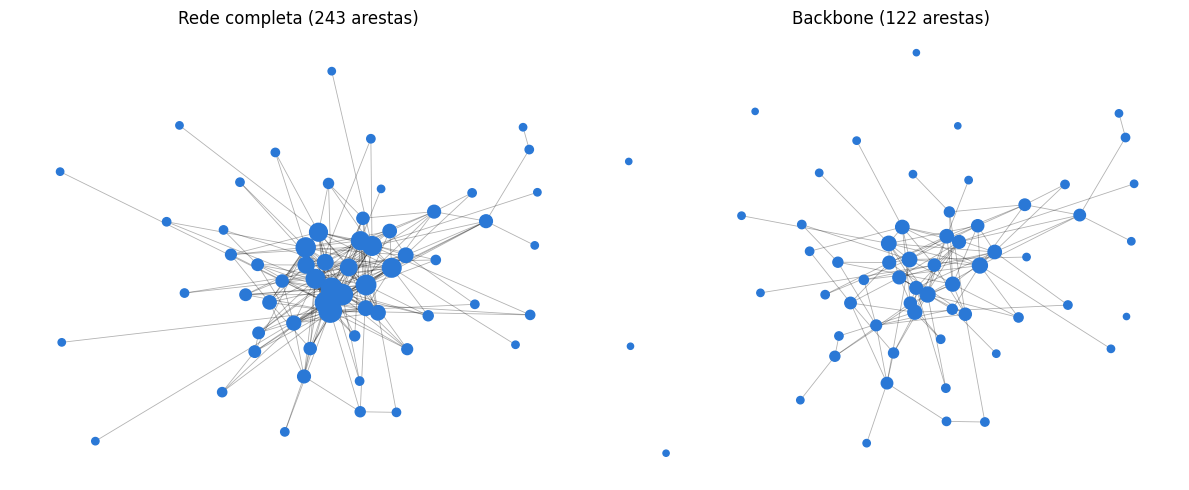

In [21]:
def backbone(G, limiar):
    H = nx.Graph()
    H.add_nodes_from(G.nodes(data=True))
    H.add_edges_from((u, v, d) for u, v, d in G.edges(data=True) if d["weight"] >= limiar)
    return H

Q_ESCOLHIDO = 0.5
pesos_j = np.array([d["weight"] for _, _, d in G_jac.edges(data=True)])
LIMIAR_JAC = float(np.quantile(pesos_j, Q_ESCOLHIDO))
G_bb = backbone(G_jac, LIMIAR_JAC)

sem_liga = list(nx.isolates(G_bb))
print(f"limiar Jaccard: {LIMIAR_JAC:.4f} | arestas: {G_jac.number_of_edges()} -> {G_bb.number_of_edges()}")
print("categorias que perdem todas as ligações:", sorted(sem_liga))

pos = nx.spring_layout(G_jac, seed=42, weight="weight")
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, G, t in zip(ax, [G_jac, G_bb], ["Rede completa", "Backbone"]):
    nx.draw_networkx_edges(G, pos, ax=a, alpha=0.3, width=0.6)
    nx.draw_networkx_nodes(G, pos, ax=a, node_size=[20 + 8 * G.degree(n) for n in G], node_color=CAT[0])
    a.set_title(f"{t} ({G.number_of_edges()} arestas)")
    a.axis("off")
plt.tight_layout()
plt.savefig(FIG_DIR / "05_backbone.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretação:** Para o processo de encontrar o backbone da rede, foi utilizado um quantile de 0.5 que é usado para retirar arestas que estão nos 50% menores Jaccard, reduzindo o número de arestas de 243 para 122. As categorias que perdem todas suas ligações são categorias que não compartilham pedidos entre si.

### Hubs e pontes no circos e no arc plot (semana 4)

No circos, os nós ficam agrupados por papel (hub, ponte, outra) e as arestas laranja são as que tocam uma ponte. No arc plot, os nós ficam ordenados por grau e coloridos pelo mesmo papel.

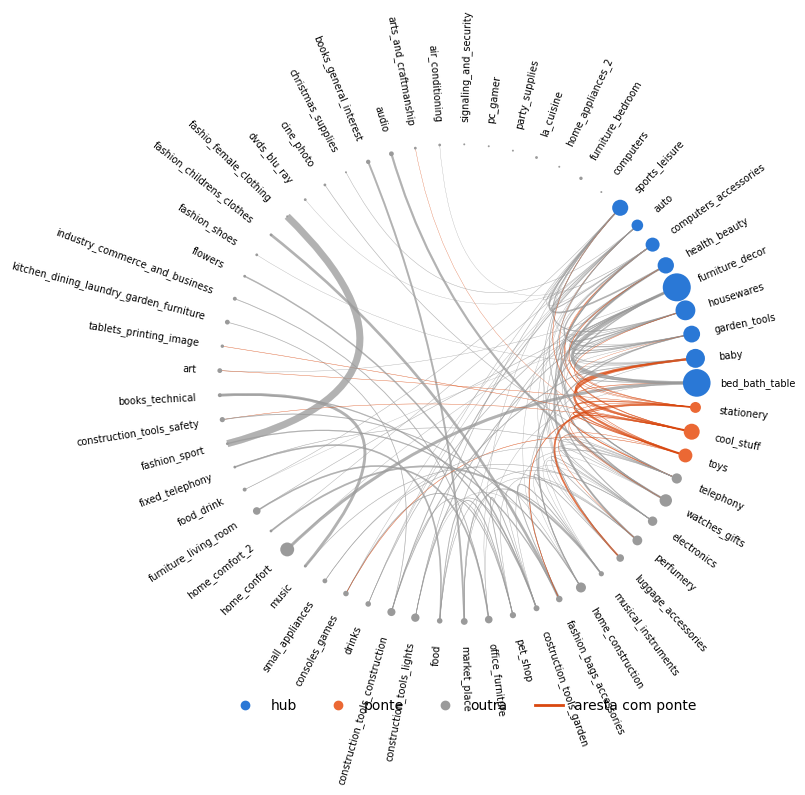

In [22]:
from nxviz import annotate
from matplotlib.lines import Line2D

for n in G_bb.nodes:
    G_bb.nodes[n]["grau"] = int(G_bb.degree(n))
    G_bb.nodes[n]["papel"] = ("hub" if cent.loc[n, "hub"]
                              else "ponte" if cent.loc[n, "ponte"] else "outra")
    G_bb.nodes[n]["tam_arc"] = G_bb.nodes[n]["n_unidades"] + 300
PAL_PAPEL = {"hub": CAT[0], "ponte": CAT[1], "outra": COR_OUTRAS}

COR_NORMAL, COR_PONTE = "#9A9A9A", "#D9480F"
for u, v, d in G_bb.edges(data=True):
    d["ligacao"] = ("com ponte" if "ponte" in (G_bb.nodes[u]["papel"], G_bb.nodes[v]["papel"])
                    else "demais")

plt.figure(figsize=(7, 7))
nv.circos(
    G_bb, group_by="papel", sort_by="grau",
    node_color_by="papel", node_size_by="n_unidades", node_palette=PAL_PAPEL,
    edge_lw_by="weight", edge_color_by="ligacao",
    node_enc_kwargs={"size_scale": 0.08},
    edge_enc_kwargs={"lw_scale": 10, "alpha_scale": 5},
    edge_palette={"demais": COR_NORMAL, "com ponte": COR_PONTE},
)
annotate.circos_labels(G_bb, group_by="papel", sort_by="grau",
                       layout="rotate", radius_offset=1.5, fontdict={"size": 7})
plt.legend(handles=[Line2D([0], [0], marker="o", ls="", color=c, label=k) for k, c in PAL_PAPEL.items()]
           + [Line2D([0], [0], color=COR_PONTE, lw=2, label="aresta com ponte")],
           loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=4, frameon=False)
plt.savefig(FIG_DIR / "07_circos_projecao.png", dpi=150, bbox_inches="tight")
plt.show()


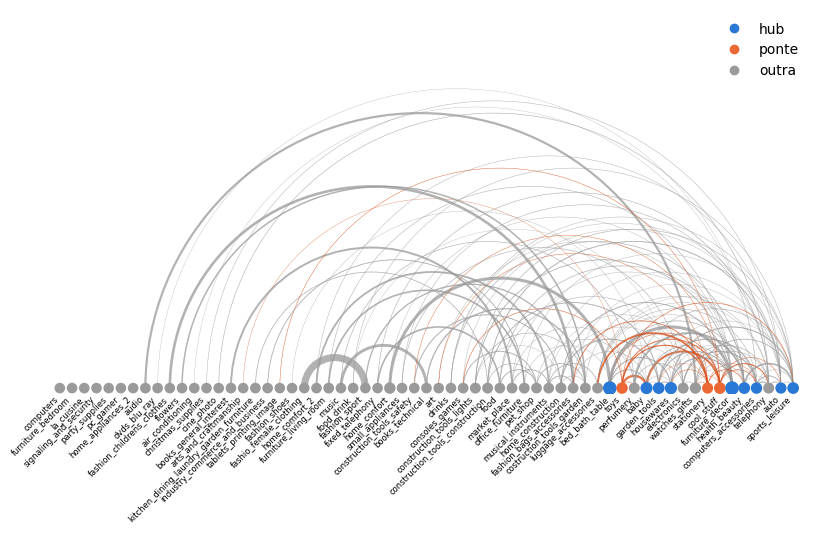

In [23]:
plt.figure(figsize=(10, 5))
nv.arc(
    G_bb, sort_by="grau",
    node_color_by="papel", node_size_by="tam_arc", node_palette=PAL_PAPEL,
    edge_color_by="ligacao", edge_lw_by="weight",
    node_enc_kwargs={"size_scale": 0.05},
    edge_enc_kwargs={"lw_scale": 10, "alpha_scale": 5},
    edge_palette={"demais": COR_NORMAL, "com ponte": COR_PONTE},
)
annotate.arc_labels(G_bb, sort_by="grau", layout="standard", fontdict={"size": 6})
plt.legend(handles=[Line2D([0], [0], marker="o", ls="", color=c, label=k) for k, c in PAL_PAPEL.items()],
           loc="upper right", frameon=False)
plt.savefig(FIG_DIR / "08_arc.png", dpi=150, bbox_inches="tight")
plt.show()
